# ASL Alphabet Recognition — Data Understanding, Data Quality & Preprocessing

> **Review:**  Chú ý nhất là dataset **không có exact duplicate theo MD5**, nhưng có **near-duplicate / chuỗi ảnh liên tiếp rất giống nhau** => không dùng random image-wise split mà dùng **capture-block-aware split** để giảm leakage.

### Pipeline tổng quát

`Raw dataset → Structure audit → Visual audit → Image quality → Corruption → Exact duplicate → Near-duplicate / sequence audit → Capture blocks → Group-aware split → Augmentation/Normalization → Dataset/DataLoader → Sanity check`

### Note khi trình bày output

- `0 exact duplicates` chỉ có nghĩa là không có hai file có **cùng MD5**; không có nghĩa là dataset không có ảnh gần giống nhau.
- Các mốc capture block là kết quả của **visual inspection + brightness trend + SSIM + cross-class verification**, không chỉ dựa vào một chỉ số.
- Validation được giữ ở một capture regime riêng để đánh giá khó hơn và tránh near-duplicate leakage.
- Dataset là ảnh tĩnh; với các ký hiệu động như **J** và **Z**, mô hình chỉ học representation tĩnh có trong dataset chứ chưa mô hình hóa chuyển động thực tế.


In [4]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path(".")
TRAIN_DIR = DATA_DIR / "asl_alphabet_train"
TEST_DIR  = DATA_DIR / "asl_alphabet_test"

### Kiểm tra đường dẫn có hợp lệ 



In [5]:
print("Train tồn tại:", TRAIN_DIR.exists())
print("Test tồn tại :", TEST_DIR.exists())


Train tồn tại: True
Test tồn tại : True


### 1.2. Đọc danh sách class từ cấu trúc thư mục

Mỗi thư mục con trong `asl_alphabet_train` được xem là một label. Cách làm này tránh hard-code class name và đảm bảo label phản ánh đúng cấu trúc dữ liệu trên ổ đĩa.

**Output:** 29 class gồm A–Z và `del`, `nothing`, `space`. Đây là số class sẽ được dùng cho output layer của classifier sau này.


In [6]:
class_names = sorted([
    folder.name
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
])

print("Số class:", len(class_names))
print("Classes:", class_names)

Số class: 29
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


## 2. Tạo DataFrame chỉ mục cho toàn bộ ảnh train

**Mục đích:** thay vì load 87,000 ảnh vào RAM, t chỉ lưu `Path` và `Class` trong `df_train`. Đây là index trung tâm cho toàn bộ audit, split và dataset của PyTorch.

- `IMAGE_EXTENSIONS`: giới hạn loại file ảnh được chấp nhận.
- Vòng lặp duyệt từng class folder và từng file ảnh.
- Mỗi ảnh tạo một record `{Path, Class}`.

**Output:** 87,000 ảnh được index. Việc `head()` hiển thị A1, A10, A100... là do sort chuỗi; vấn đề này được xử lý ở phần sequence audit bằng cách tách số ở cuối filename và sort theo số.


In [7]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff"
}

records = []

for class_dir in sorted(TRAIN_DIR.iterdir()):

    if not class_dir.is_dir():
        continue

    class_name = class_dir.name

    for image_path in sorted(class_dir.iterdir()):

        if (
            image_path.is_file()
            and image_path.suffix.lower()
            in IMAGE_EXTENSIONS
        ):

            records.append({
                "Path": str(image_path),
                "Class": class_name
            })

df_train = pd.DataFrame(records)

display(df_train.head())

print(
    "Tổng số ảnh train:",
    len(df_train)
)

,Path,Class
0,asl_alphabet_train\A\A1.jpg,A
1,asl_alphabet_train\A\A10.jpg,A
2,asl_alphabet_train\A\A100.jpg,A
3,asl_alphabet_train\A\A1000.jpg,A
4,asl_alphabet_train\A\A1001.jpg,A


Tổng số ảnh train: 87000


### 2.1. Kiểm tra cân bằng class

**Mục đích:** xác định liệu cần class weighting, oversampling hay undersampling hay không.

**Output:** mỗi class có đúng 3,000 ảnh; min = max = 3,000. Dataset cân bằng, không cần xử lý imbalance.


In [8]:
class_distribution = (
    df_train["Class"]
    .value_counts()
    .sort_index()
)

display(class_distribution)

print(
    "Min images/class:",
    class_distribution.min()
)

print(
    "Max images/class:",
    class_distribution.max()
)

Class
A          3000
B          3000
C          3000
D          3000
E          3000
F          3000
G          3000
H          3000
I          3000
J          3000
K          3000
L          3000
M          3000
N          3000
O          3000
P          3000
Q          3000
R          3000
S          3000
T          3000
U          3000
V          3000
W          3000
X          3000
Y          3000
Z          3000
del        3000
nothing    3000
space      3000
Name: count, dtype: int64

Min images/class: 3000
Max images/class: 3000


## 3. Visual audit — xem một ảnh đại diện cho mỗi class

**Mục đích:** kiểm tra  chất lượng dữ liệu bằng mắt trước khi dùng các kiểm tra định lượng.

Mục đích hàm lấy một ảnh từ mỗi class và vẽ theo grid. Cần xem:

- background/góc chụp camera có quá đồng nhất hay không
- hand pose có hợp lý với label không
- có blur, crop lỗi, hoặc tay bị cắt không
- những class nào có hình dáng gần nhau và có thể gây confusion

**Nhận xét từ output:** background khá đồng nhất; nhiều class nhìn rõ, nhưng các nhóm như M/N, U/V/R, A/S, G/H, P/Q có khả năng dễ nhầm
=> Sau cần confusion matrix và per-class metrics.


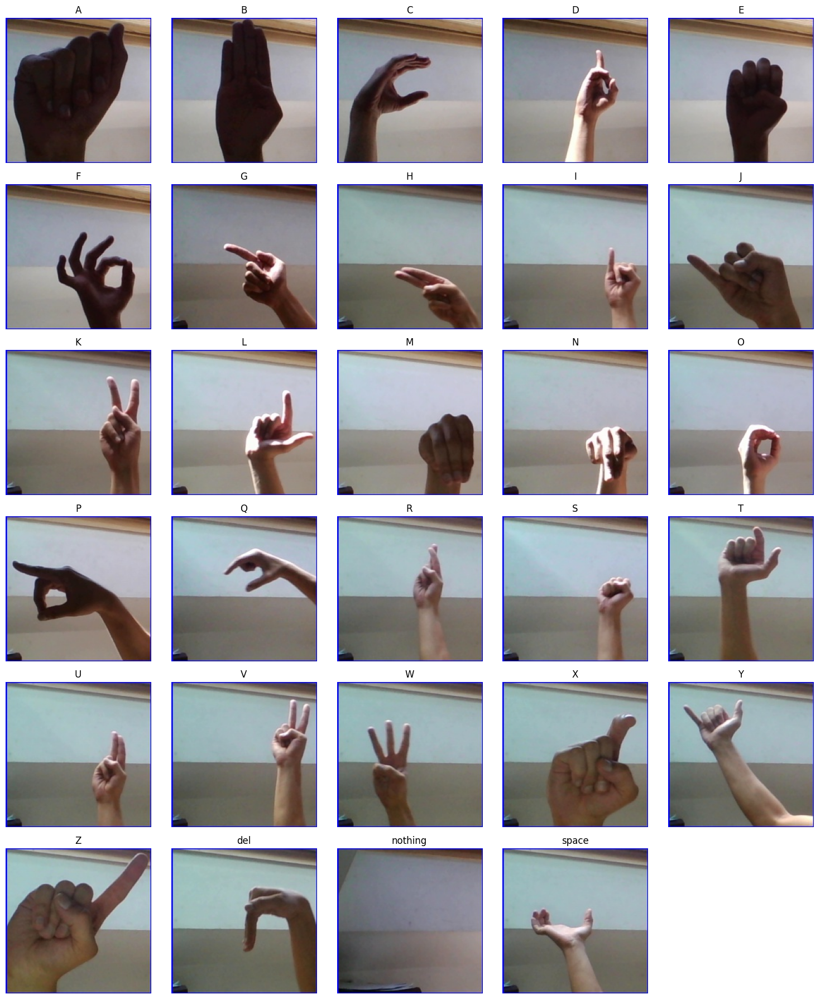

In [9]:
import math
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def show_one_sample_per_class(
    df,
    seed=42
):
    classes = sorted(
        df["Class"].unique()
    )

    cols = 5
    rows = math.ceil(
        len(classes) / cols
    )

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(15, 3 * rows)
    )

    axes = np.array(
        axes
    ).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, class_name in zip(
        axes,
        classes
    ):
        subset = df[
            df["Class"] == class_name
        ]

        row = subset.sample(
            n=1,
            random_state=seed
        ).iloc[0]

        image = Image.open(
            row["Path"]
        ).convert("RGB")

        ax.imshow(image)
        ax.set_title(class_name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_one_sample_per_class(
    df_train
)

## 4. Audit kích thước và color mode trên mẫu phân tầng

Quét toàn bộ 87,000 ảnh nhiều lần tốn tài nguyên(lần đầu chạy 15p chưa xong) => giải pháp lấy **100 ảnh/class = 2,900 ảnh** để kiểm tra nhanh size và color mode.

`groupby("Class").sample(...)` đảm bảo mỗi class đóng góp số ảnh bằng nhau, tránh mẫu bị lệch về một class nào đó.



In [10]:
SAMPLE_PER_CLASS = 100

sample_df = (
    df_train
    .groupby("Class", group_keys=False)
    .sample(
        n=SAMPLE_PER_CLASS,
        random_state=42
    )
)

print("Số ảnh được kiểm tra:", len(sample_df))

Số ảnh được kiểm tra: 2900


### 4.1. Đọc metadata ảnh mẫu

Mỗi ảnh trong `sample_df` được mở bằng PIL để lấy:

- `Width`, `Height`;
- `Mode` (RGB, grayscale...);
- lỗi đọc nếu có.

**Output:** 2,900/2,900 ảnh được đọc, tất cả là `200×200` và `RGB`( được mô tả trong kaggle nhưng vẫn ktra cho kĩ ).Full scan ở bước tiếp theo kiểm tra readability/corruption trên toàn bộ 87,000 ảnh và đồng thời lưu width/height/mode vào `df_audit`.

> Nếu cần ghi trong báo cáo rằng *toàn bộ* 87,000 ảnh đều 200×200 RGB, có thể tổng hợp trực tiếp `df_audit.groupby(["Width","Height"])` và `df_audit["Mode"].value_counts()` mà không cần đọc lại file.


In [11]:
image_info = []
read_errors = []

for row in sample_df.itertuples(index=False):

    image_path = Path(row.Path)

    try:
        with Image.open(image_path) as img:

            width, height = img.size

            image_info.append({
                "Path": str(image_path),
                "Class": row.Class,
                "Width": width,
                "Height": height,
                "Mode": img.mode
            })

    except Exception as e:

        read_errors.append({
            "Path": str(image_path),
            "Class": row.Class,
            "Error": str(e)
        })


df_image_info = pd.DataFrame(image_info)

print("Ảnh kiểm tra thành công:", len(df_image_info))
print("Lỗi đọc:", len(read_errors))

print("\nKích thước:")
display(
    df_image_info
    .groupby(["Width", "Height"])
    .size()
    .rename("Count")
)

print("\nColor mode:")
display(
    df_image_info["Mode"]
    .value_counts()
)

Ảnh kiểm tra thành công: 2900
Lỗi đọc: 0

Kích thước:


Width  Height
200    200       2900
Name: Count, dtype: int64


Color mode:


Mode
RGB    2900
Name: count, dtype: int64

## 5. Full integrity audit + MD5 trong một lượt quét

Mỗi file được xử lý theo ba bước:

1. Mở ảnh và ghi metadata (`Width`, `Height`, `Mode`)
2. `img.verify()` để phát hiện file bị hỏng/corrupt
3. Tính MD5 từ bytes của file để tìm xem có exact-duplicate hay không

Gộp ba việc trong một vòng lặp tránh phải scan ổ đĩa nhiều lần

**Output:** 87,000 ảnh đều `Readable`, `Corrupted = 0` => không cần loại bỏ ảnh hỏng


In [12]:

from pathlib import Path
from PIL import Image
import hashlib
import pandas as pd
from tqdm.auto import tqdm

def calculate_md5(file_path, chunk_size=8192):
    md5 = hashlib.md5()

    with open(file_path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            md5.update(chunk)

    return md5.hexdigest()


audit_records = []

for row in tqdm(
    df_train.itertuples(index=False),
    total=len(df_train),
    desc="Auditing images"
):
    image_path = Path(row.Path)

    record = {
        "Path": str(image_path),
        "Class": row.Class,
        "Readable": True,
        "Width": None,
        "Height": None,
        "Mode": None,
        "MD5": None,
        "Error": None
    }

    try:
        # Đọc metadata ảnh
        with Image.open(image_path) as img:
            record["Width"], record["Height"] = img.size
            record["Mode"] = img.mode

            # verify để check corruption
            img.verify()

        # Tính MD5 sau khi verify
        record["MD5"] = calculate_md5(
            image_path
        )

    except Exception as e:
        record["Readable"] = False
        record["Error"] = str(e)

    audit_records.append(record)


df_audit = pd.DataFrame(
    audit_records
)

print("Tổng ảnh:", len(df_audit))
print(
    "Readable:",
    df_audit["Readable"].sum()
)
print(
    "Corrupted:",
    (~df_audit["Readable"]).sum()
)

Auditing images:   0%|          | 0/87000 [00:00<?, ?it/s]

Tổng ảnh: 87000
Readable: 87000
Corrupted: 0


### 5.1. Lưu kết quả audit

`df_audit`  lưu thành `image_audit.csv` để những lần chạy sau không cần tính lại MD5 và verify toàn bộ 87,000 ảnh

In [13]:
df_audit.to_csv(
    "image_audit.csv",
    index=False
)

print("Đã lưu image_audit.csv")

Đã lưu image_audit.csv


## 6. Exact duplicate detection bằng MD5

Nhóm các ảnh có cùng MD5 và chỉ giữ các nhóm có từ hai file trở lên.

**Ý nghĩa:** cùng MD5 nghĩa là hai file có nội dung bytes giống hệt nhau, khác với near-duplicate (ảnh nhìn gần giống nhưng bytes khác).


In [14]:
duplicate_groups = (
    df_audit[
        df_audit["Readable"]
    ]
    .groupby("MD5")
    .filter(
        lambda x: len(x) > 1
    )
)

### 6.1. Đếm duplicate groups và duplicate files dư thừa

- `Số duplicate groups`: số hash xuất hiện nhiều hơn một lần.
- `Số extra duplicate files`: số file dư nếu mỗi nhóm chỉ giữ một bản.

**Output:** cả hai đều bằng 0, không phát hiện exact duplicate theo MD5.


In [15]:
duplicate_hash_counts = (
    duplicate_groups
    .groupby("MD5")
    .size()
    .sort_values(
        ascending=False
    )
)

print(
    "Số duplicate groups:",
    len(
        duplicate_hash_counts
    )
)

print(
    "Số extra duplicate files:",
    int(
        (
            duplicate_hash_counts
            - 1
        ).sum()
    )
)

Số duplicate groups: 0
Số extra duplicate files: 0


### 6.2. Kiểm tra duplicate khác label

Để tìm trường hợp cùng một file xuất hiện dưới nhiều nhãn khác nhau — một dạng label conflict
 
**Output:** 0 conflict. Hợp lý ( vì duplicate group = 0)


In [16]:
label_conflict_hashes = []

for md5_hash, group in (
    duplicate_groups.groupby("MD5")
):

    if group["Class"].nunique() > 1:
        label_conflict_hashes.append(
            md5_hash
        )

print(
    "Duplicate groups khác label:",
    len(label_conflict_hashes)
)

Duplicate groups khác label: 0


## 7. Chuẩn hóa thứ tự ảnh theo số ở cuối filename

Tên file như A1, A10, A100 nếu sort dạng chuỗi sẽ không phản ánh đúng thứ tự số học. Hàm extract_image_number dùng regex để lấy phần số ở cuối filename.

Ví dụ: `A1001.jpg → 1001`.

quan trọng cho sequence audit, vì ta cần so sánh đúng ảnh liên tiếp `i → i+1`.


In [17]:
import re

def extract_image_number(path):
    filename = Path(path).stem

    match = re.search(r'(\d+)$', filename)

    if match:
        return int(match.group(1))

    return -1

### 7.1. Hàm visualize chuỗi ảnh theo đúng thứ tự số

`show_sequence`:

1. lọc một class;
2. tạo `ImageNumber`;
3. sort tăng dần theo số;
4. chọn một đoạn liên tiếp bằng `iloc[start:start+n]`;
5. vẽ grid để quan sát sự thay đổi frame-to-frame.

Lưu ý: `start` là **vị trí sau khi sort**, nên `start=990` tương ứng bắt đầu khoảng image number 991.


In [18]:
def show_sequence(
    df,
    class_name,
    start=0,
    n=12
):
    subset = (
        df[df["Class"] == class_name]
        .copy()
    )

    subset["ImageNumber"] = (
        subset["Path"]
        .apply(extract_image_number)
    )

    subset = (
        subset
        .sort_values("ImageNumber")
        .reset_index(drop=True)
    )

    sample = subset.iloc[
        start:start+n
    ]

    cols = 4
    rows = math.ceil(
        len(sample) / cols
    )

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(12, 3 * rows)
    )

    axes = np.array(
        axes
    ).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(
        axes,
        sample.iterrows()
    ):
        image = Image.open(
            row["Path"]
        ).convert("RGB")

        ax.imshow(image)

        ax.set_title(
            Path(row["Path"]).name,
            fontsize=8
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

### 7.2. Kiểm tra sequence đầu tiên trên nhiều class

Visualize A, M, N, T ở đầu chuỗi để kiểm tra xem các ảnh liên tiếp có tương quan mạnh hay không.

**Output:** các frame liên tiếp rất giống nhau về hand pose, background và framing. Điều này cho thấy dataset có **near-duplicate / sequential correlation**, dù MD5 không phát hiện exact duplicate.


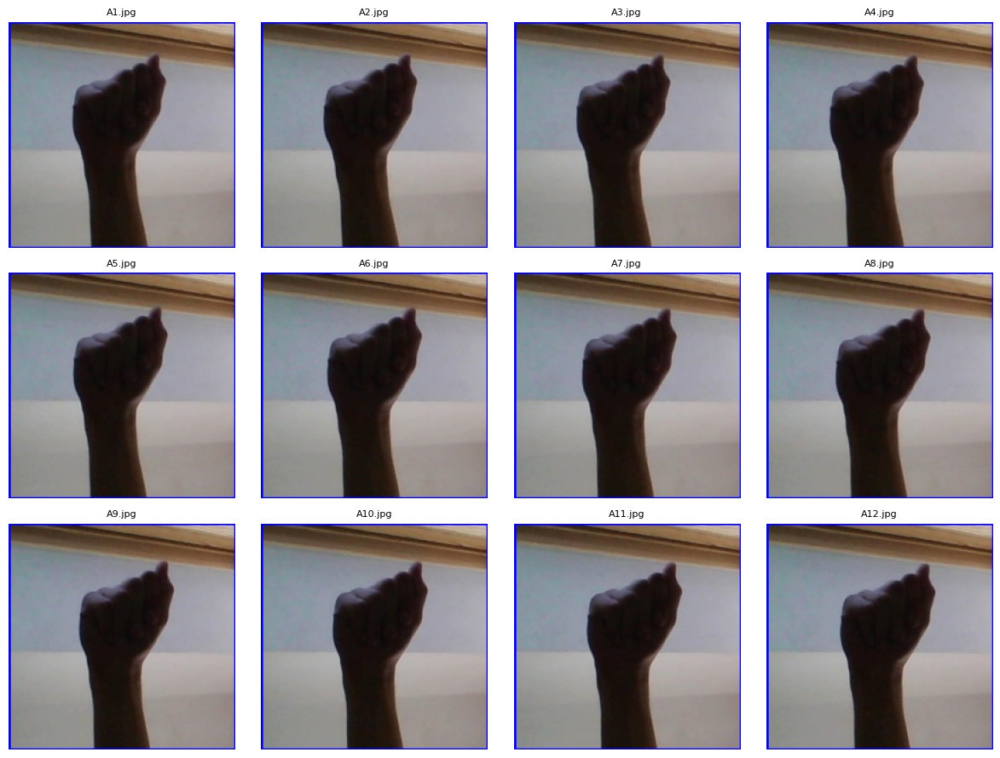

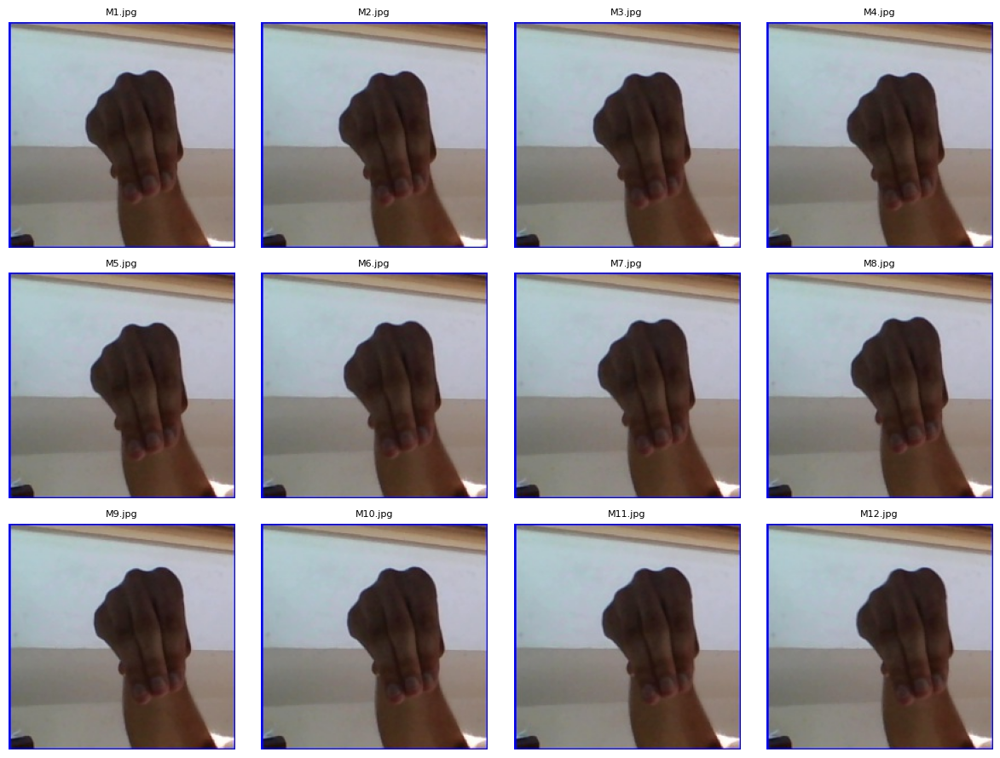

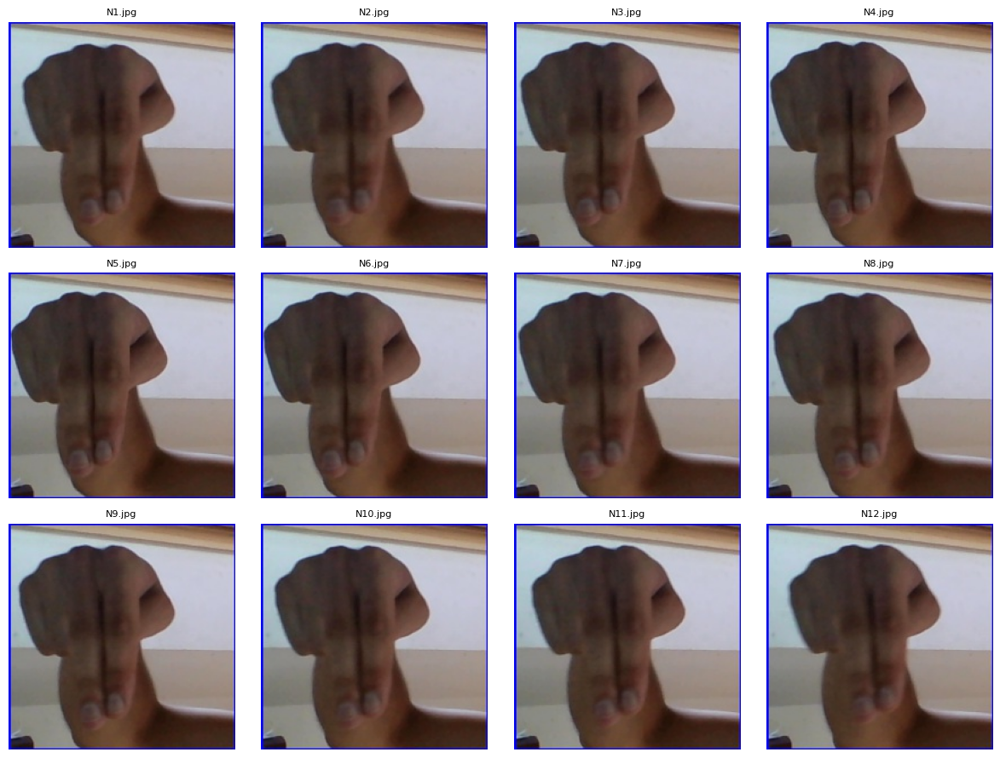

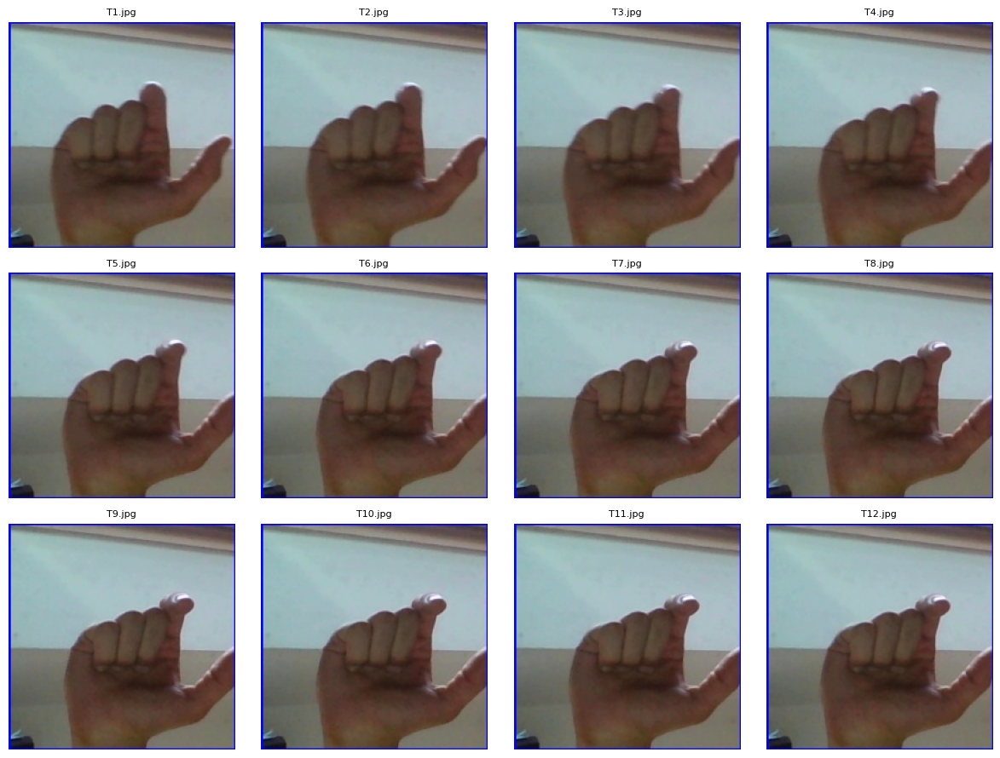

In [19]:
show_sequence(
    df_train,
    "A",
    start=0,
    n=12
)

show_sequence(
    df_train,
    "M",
    start=0,
    n=12
)

show_sequence(
    df_train,
    "N",
    start=0,
    n=12
)

show_sequence(
    df_train,
    "T",
    start=0,
    n=12
)

### 7.3. Kiểm tra các vùng biên trên class A

Xem các đoạn quanh đầu chuỗi, khoảng 1000, khoảng 2000 và cuối chuỗi. Mục đích là tìm các điểm mà capture condition thay đổi đột ngột.

Visual inspection ban đầu cho thấy thay đổi rõ quanh `1000→1001` và `2000→2001`. Đây mới là giả thuyết ban đầu, chưa phải kết luận cuối cùng.


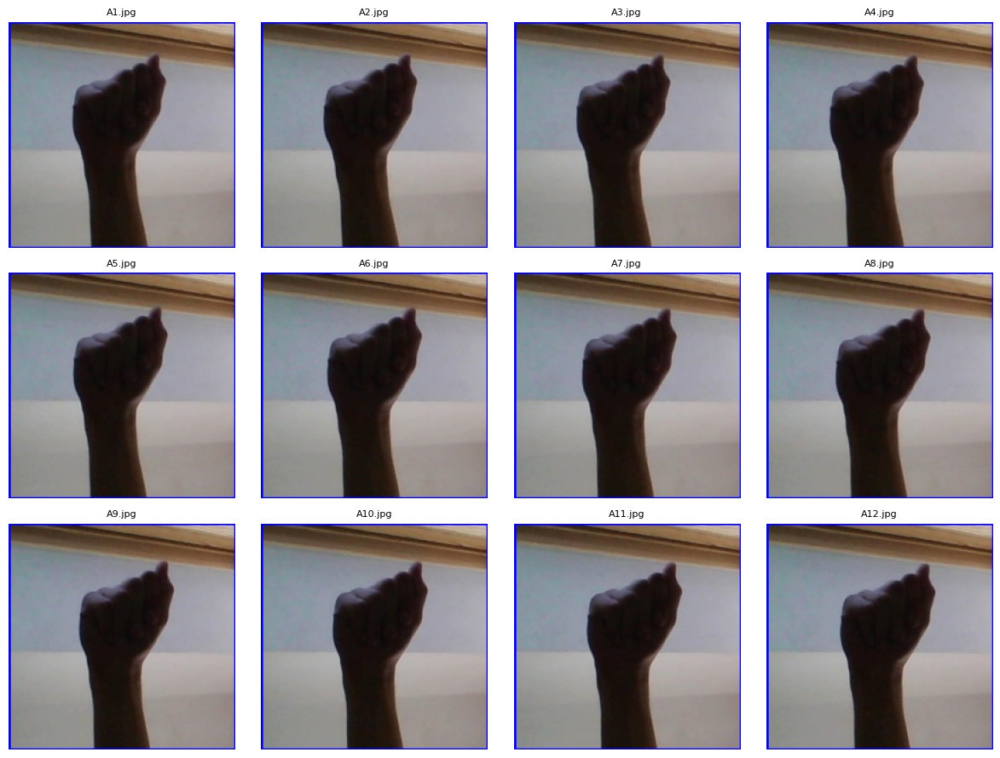

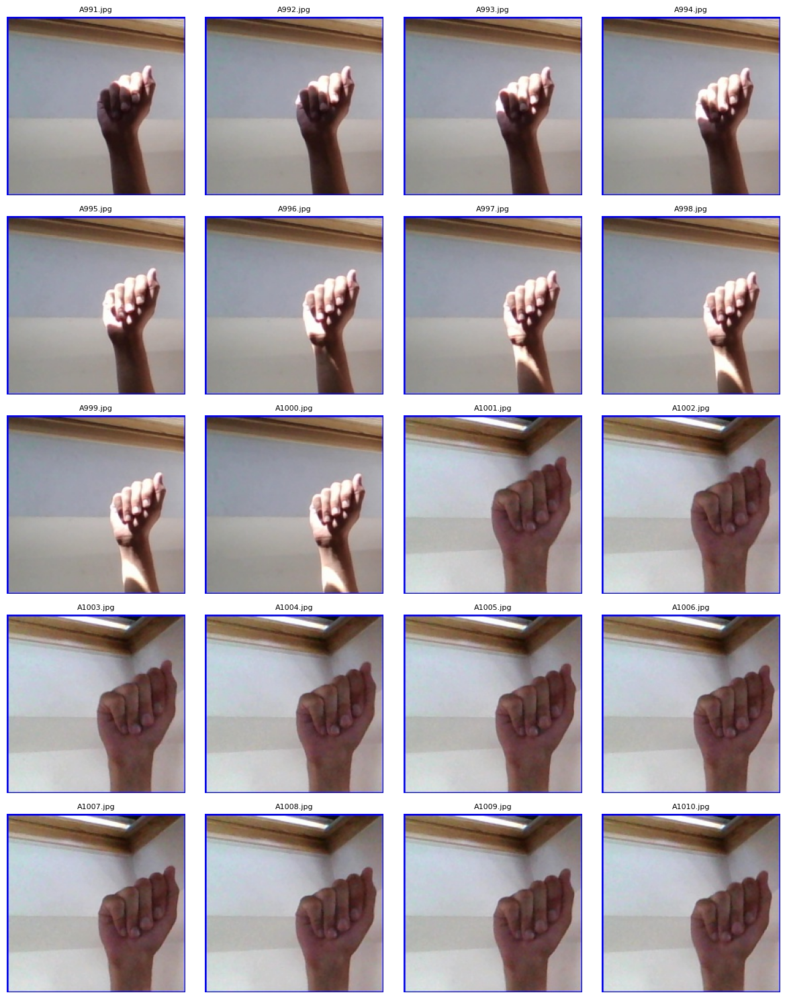

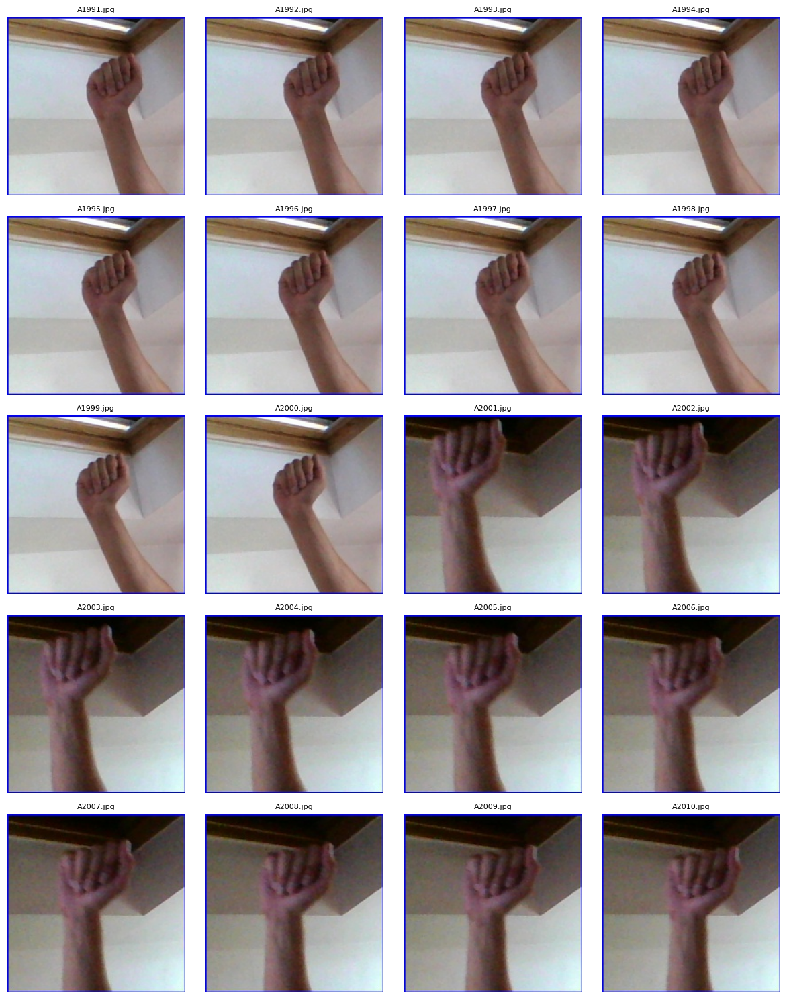

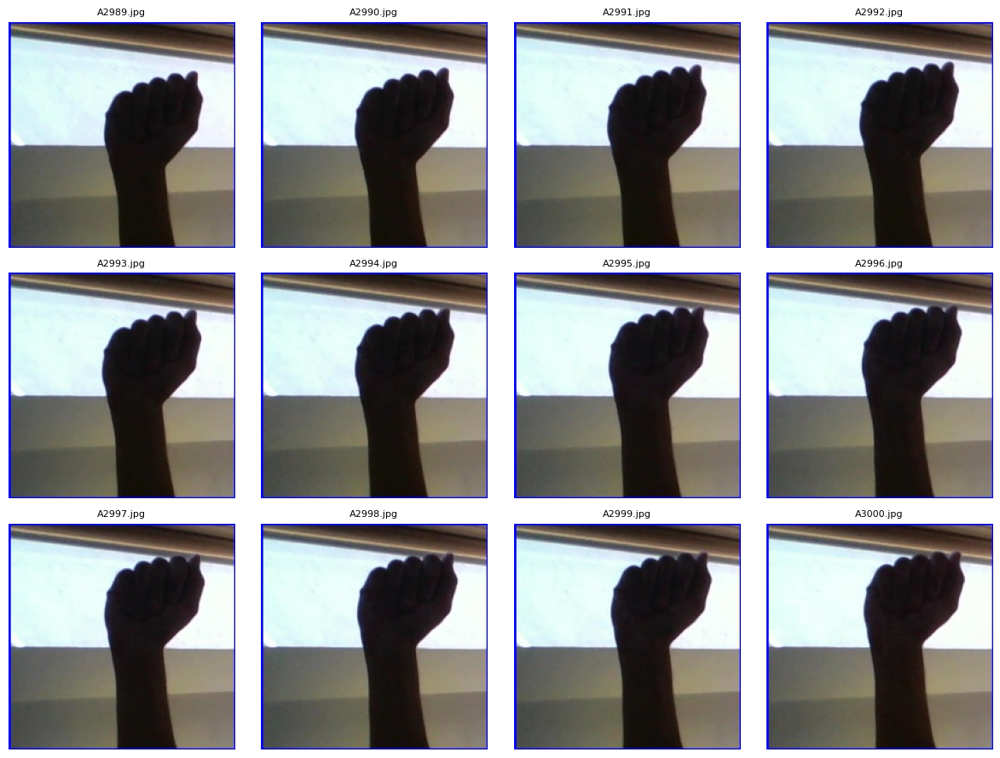

In [20]:
show_sequence(df_train, "A", start=0, n=12)

show_sequence(df_train, "A", start=990, n=20)

show_sequence(df_train, "A", start=1990, n=20)

show_sequence(df_train, "A", start=2988, n=12)

### 7.4. Kiểm tra giả thuyết trên các class khác

Lặp visual sequence cho M, N, T nhằm tránh kết luận chỉ dựa trên class A.

Việc cùng một mốc thay đổi xuất hiện ở nhiều class là bằng chứng mạnh hơn rằng đó là **capture-regime boundary** chứ không chỉ là chuyển động riêng của một gesture.


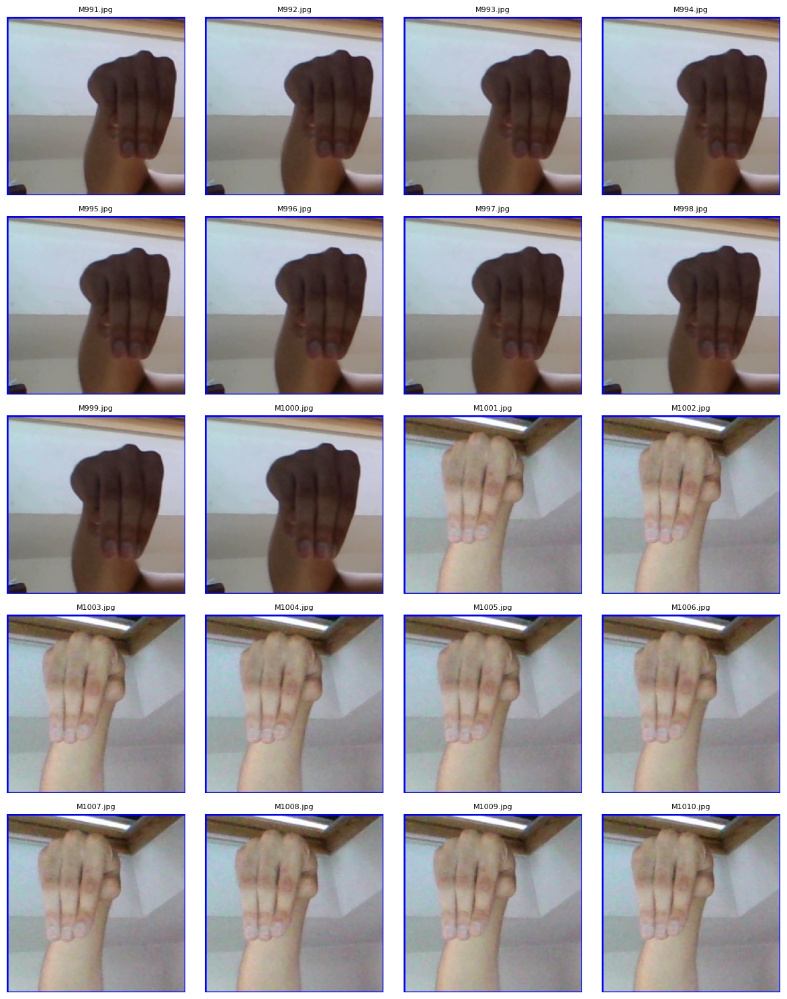

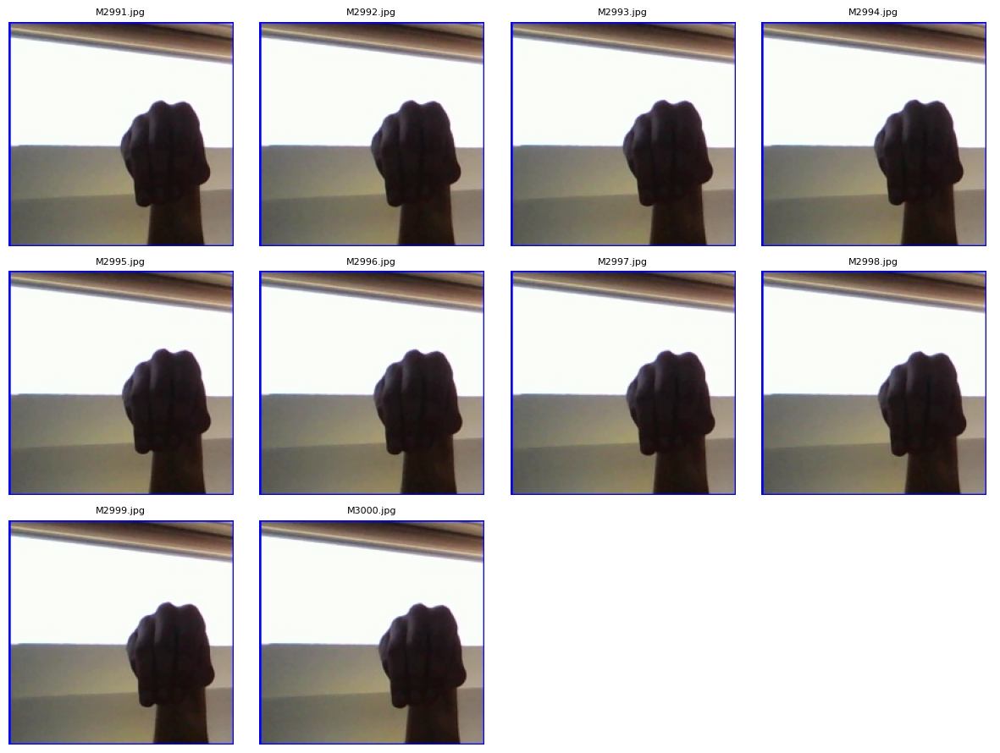

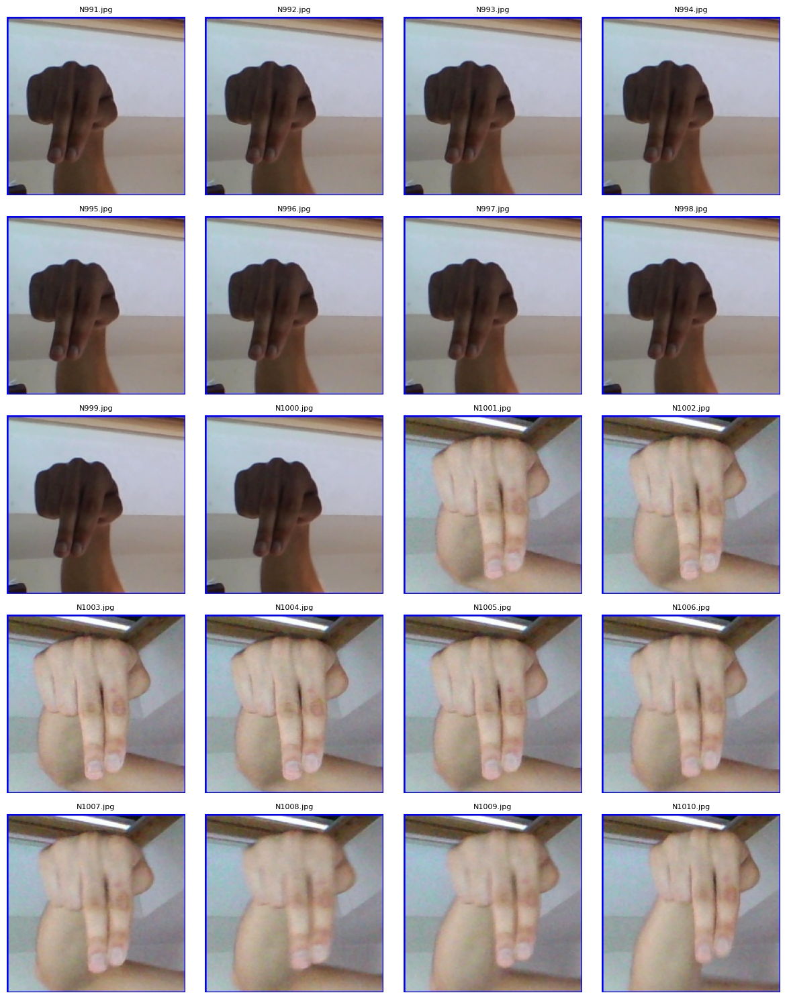

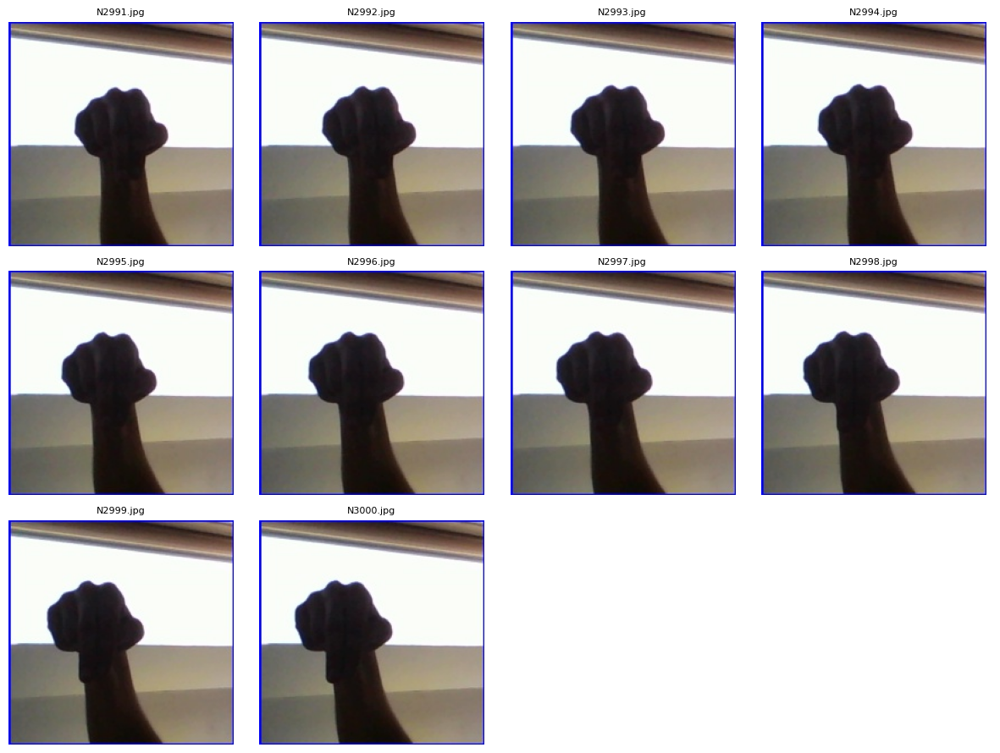

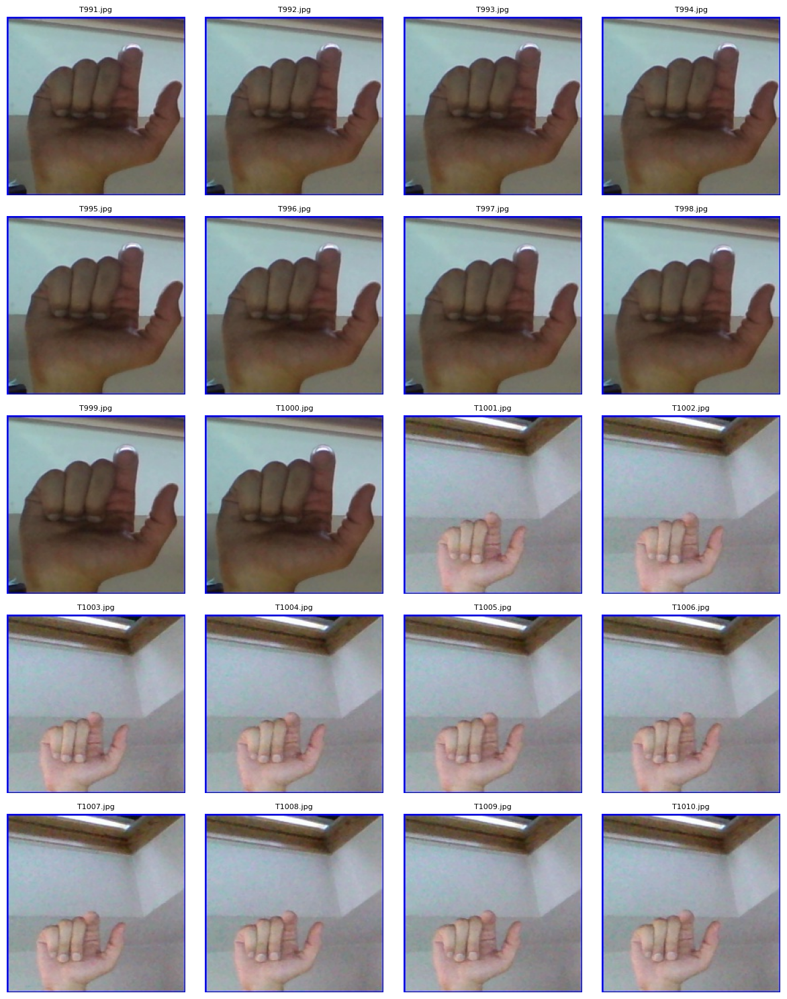

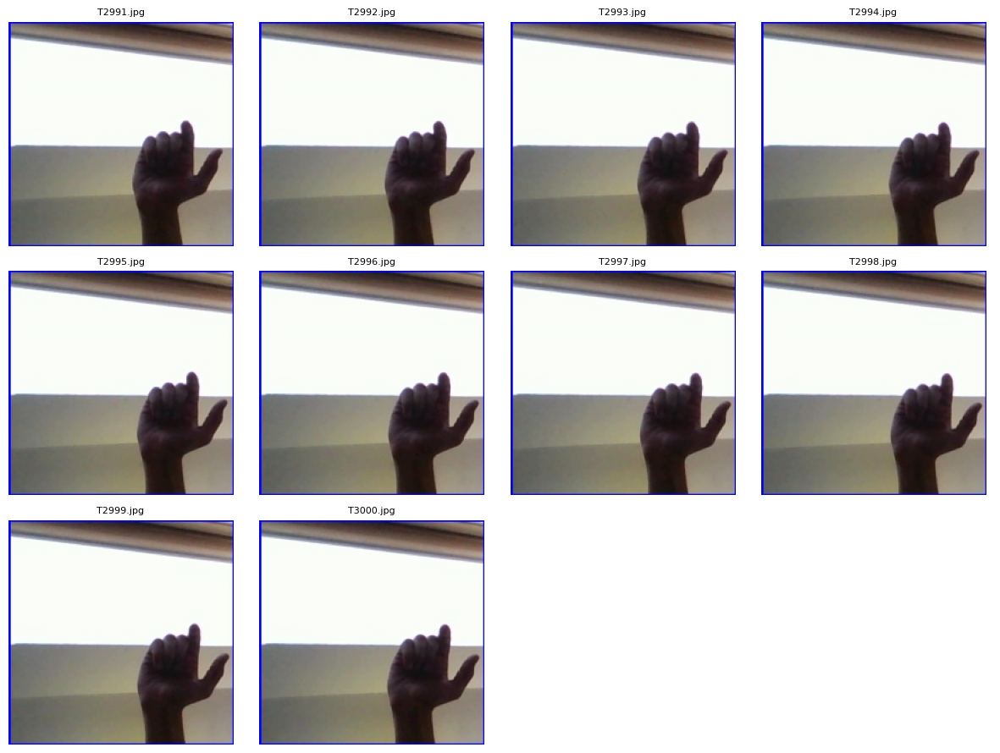

In [21]:
for class_name in ["M", "N", "T"]:

    show_sequence(
        df_train,
        class_name,
        start=990,
        n=20
    )

    show_sequence(
        df_train,
        class_name,
        start=2990,
        n=20
    )

## 8. Brightness audit — hỗ trợ, không dùng một mình để chia block ( tức là kết hợp các điều kiện lại )
Tính mean grayscale brightness cho từng ảnh của class A theo `ImageNumber`.

**Mục đích:** xem ánh sáng/exposure có biến đổi theo chuỗi và có discontinuity quanh các candidate boundary hay không.

Brightness có thể drift liên tục ngay trong cùng một capture regime, nên nó chỉ là bằng chứng phụ trợ. Notebook không dùng brightness đơn lẻ để quyết định block.


In [22]:
brightness_records = []

subset = (
    df_train[df_train["Class"] == "A"]
    .copy()
)

subset["ImageNumber"] = (
    subset["Path"]
    .apply(extract_image_number)
)

subset = subset.sort_values("ImageNumber")

for row in subset.itertuples(index=False):
    image = Image.open(row.Path).convert("L")
    arr = np.asarray(image, dtype=np.float32)

    brightness_records.append({
        "ImageNumber": row.ImageNumber,
        "Brightness": arr.mean()
    })

df_brightness = pd.DataFrame(brightness_records)

### 8.1. Vẽ brightness theo thứ tự ảnh

Hai đường dọc ở 1000 và 2000 thể hiện các boundary đang được nghi ngờ tại thời điểm phân tích này.

Output cho thấy brightness biến động đáng kể trong từng vùng, xác nhận rằng **“block” không đồng nghĩa với brightness cố định**. Vì vậy cần thêm structural similarity và visual confirmation.


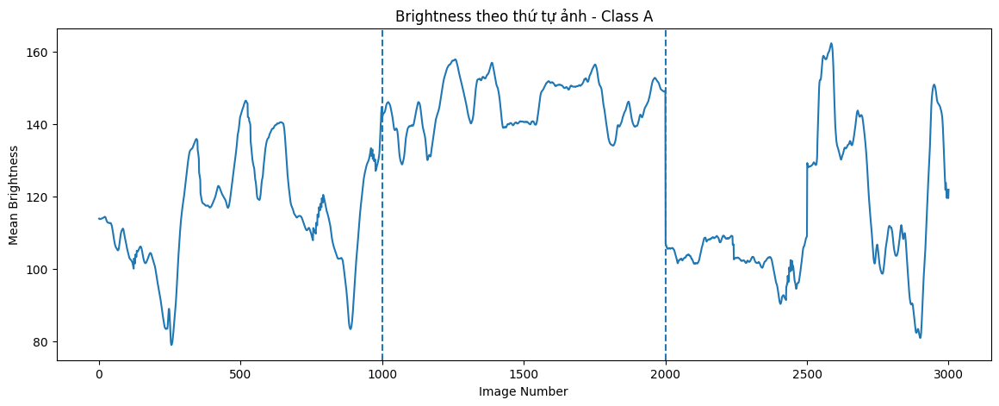

In [23]:
plt.figure(figsize=(14, 5))

plt.plot(
    df_brightness["ImageNumber"],
    df_brightness["Brightness"]
)

plt.axvline(1000, linestyle="--")
plt.axvline(2000, linestyle="--")

plt.xlabel("Image Number")
plt.ylabel("Mean Brightness")
plt.title("Brightness theo thứ tự ảnh - Class A")
plt.show()

## 9. Cài đặt scikit-image cho SSIM

In [24]:
!pip install scikit-image



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### 9.1. Tính SSIM giữa từng cặp ảnh liên tiếp của class A

Với mỗi cặp `i` và `i+1`:

- ảnh được chuyển grayscale;
- resize về 128×128 để giảm chi phí tính toán;
- tính SSIM trong khoảng gần `[-1, 1]`, thường càng gần 1 càng giống nhau.

Kết quả được lưu thành `df_ssim` với `ImageNumber1`, `ImageNumber2`, `SSIM`.

**Mục đích:** định lượng mức tương đồng frame-to-frame thay vì chỉ nhìn bằng mắt.


In [25]:
from skimage.metrics import structural_similarity as ssim
import numpy as np
from PIL import Image

sequence_records = []

subset = (
    df_train[df_train["Class"] == "A"]
    .copy()
)

subset["ImageNumber"] = (
    subset["Path"]
    .apply(extract_image_number)
)

subset = (
    subset
    .sort_values("ImageNumber")
    .reset_index(drop=True)
)

for i in range(len(subset) - 1):
    path1 = subset.loc[i, "Path"]
    path2 = subset.loc[i + 1, "Path"]

    img1 = np.asarray(
        Image.open(path1)
        .convert("L")
        .resize((128, 128)),
        dtype=np.float32
    )

    img2 = np.asarray(
        Image.open(path2)
        .convert("L")
        .resize((128, 128)),
        dtype=np.float32
    )

    score = ssim(
        img1,
        img2,
        data_range=255
    )

    sequence_records.append({
        "ImageNumber1": subset.loc[i, "ImageNumber"],
        "ImageNumber2": subset.loc[i + 1, "ImageNumber"],
        "SSIM": score
    })

df_ssim = pd.DataFrame(sequence_records)

### 9.2. Vẽ SSIM theo chuỗi

Phần lớn SSIM rất cao, chứng minh các ảnh liên tiếp có tương quan mạnh. Các cú tụt mạnh là candidate discontinuity.

Ở thời điểm vẽ graph, notebook mới đánh dấu 1000 và 2000. Sau khi xem bảng SSIM thấp nhất, mốc 2500 mới được phát hiện và kiểm tra tiếp. Vì vậy plot này nên được hiểu là **exploratory plot**, không phải định nghĩa block cuối cùng.


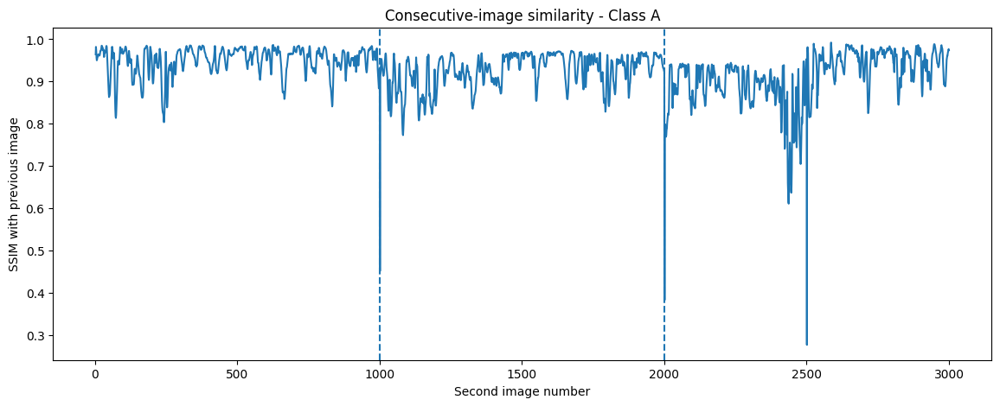

In [26]:
plt.figure(figsize=(14, 5))

plt.plot(
    df_ssim["ImageNumber2"],
    df_ssim["SSIM"]
)

plt.axvline(1000, linestyle="--")
plt.axvline(2000, linestyle="--")

plt.xlabel("Second image number")
plt.ylabel("SSIM with previous image")
plt.title("Consecutive-image similarity - Class A")

plt.show()

### 9.3. Liệt kê 20 cặp có SSIM thấp nhất

Đây là bước quan trọng để tránh nhìn graph một cách chủ quan.

**Output nổi bật:**

- `2500→2501`: SSIM ≈ 0.276 — thấp nhất;
- `2000→2001`: ≈ 0.382;
- `1000→1001`: ≈ 0.451.

Ngoài ra còn nhiều điểm thấp quanh 243x–248x. Tuy nhiên **SSIM thấp không tự động đồng nghĩa với session/capture boundary**; nó có thể do bàn tay di chuyển mạnh. Vì vậy bước tiếp theo phải quay lại visual inspection.


In [27]:
display(
    df_ssim
    .sort_values("SSIM")
    .head(20)
)

,ImageNumber1,ImageNumber2,SSIM
2499,2500,2501,0.276365
1999,2000,2001,0.382352
999,1000,1001,0.451109
2435,2436,2437,0.610682
2434,2435,2436,0.614295
2433,2434,2435,0.633378
2444,2445,2446,0.636399
2436,2437,2438,0.643188
2443,2444,2445,0.643532
2445,2446,2447,0.650331


### 9.4. Hàm so sánh trực tiếp hai ảnh

`show_pair` hiển thị hai image number cụ thể cạnh nhau để phân biệt:

- thay đổi capture condition/background/framing;
- hay chỉ là chuyển động nhỏ của bàn tay.

Đây là cách kết hợp metric định lượng (SSIM) với bằng chứng trực quan.


In [28]:
def show_pair(df, class_name, n1, n2):
    subset = df[df["Class"] == class_name].copy()
    subset["ImageNumber"] = subset["Path"].apply(extract_image_number)

    rows = subset[
        subset["ImageNumber"].isin([n1, n2])
    ].sort_values("ImageNumber")

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    for ax, (_, row) in zip(axes, rows.iterrows()):
        img = Image.open(row["Path"]).convert("RGB")
        ax.imshow(img)
        ax.set_title(Path(row["Path"]).name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

### 9.5. Xác minh các cặp SSIM thấp bằng mắt

Các cặp 1000→1001, 2000→2001 và 2500→2501 cho thấy thay đổi rõ về background/exposure/framing. Trong khi 2436→2437 và 2478→2479 chủ yếu vẫn cùng capture condition và khác do hand motion.

**Kết luận:** không dùng threshold SSIM máy móc. Boundary chỉ được chấp nhận khi có cả structural discontinuity và visual evidence.


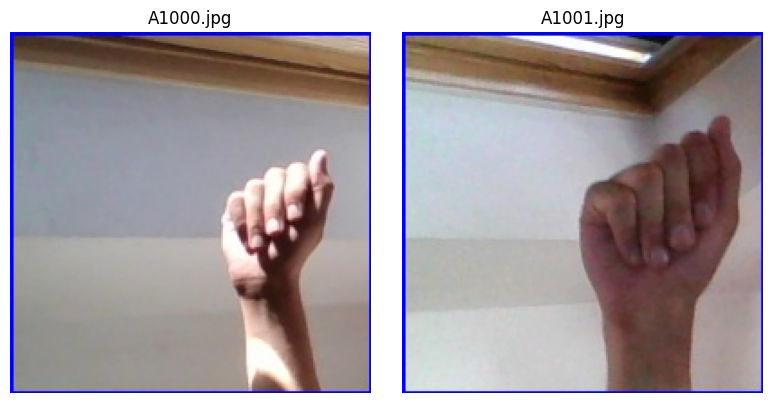

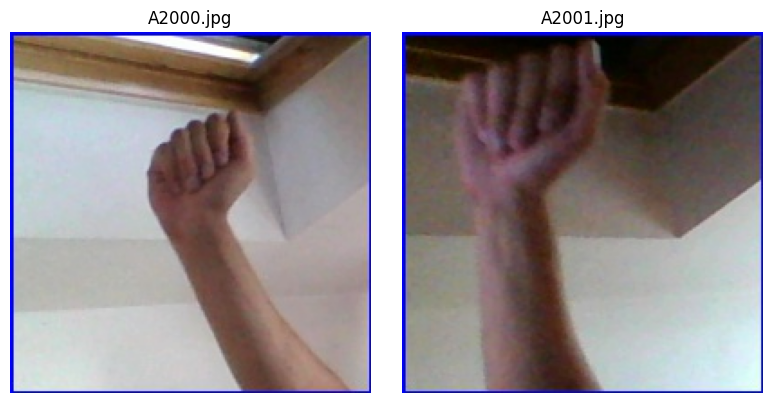

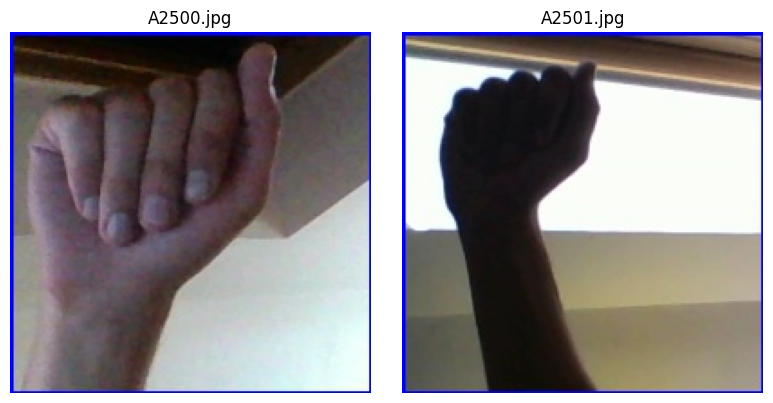

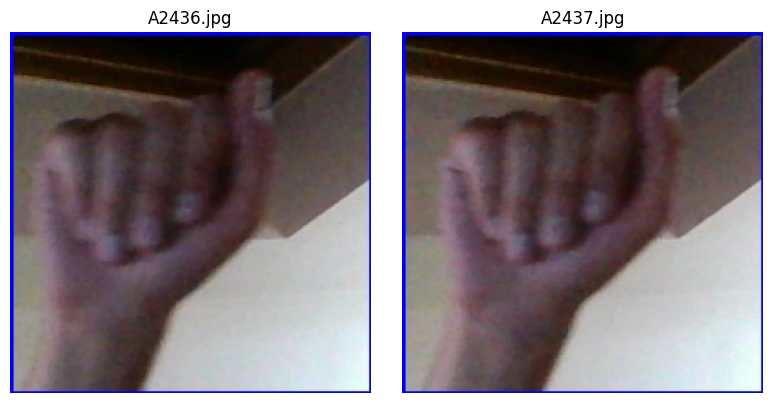

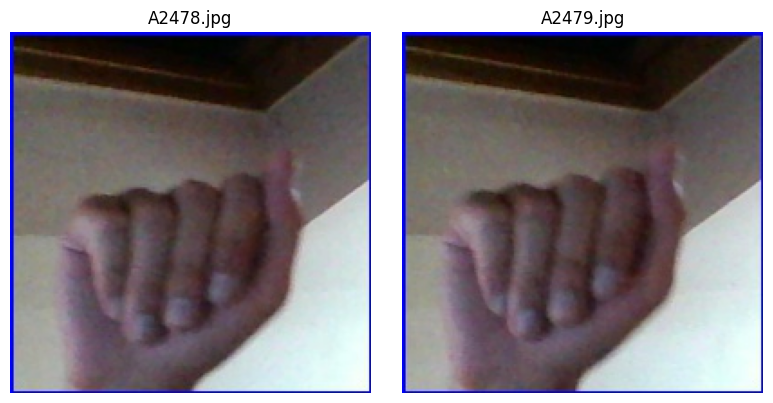

In [29]:
show_pair(df_train, "A", 1000, 1001)
show_pair(df_train, "A", 2000, 2001)
show_pair(df_train, "A", 2500, 2501)
show_pair(df_train, "A", 2436, 2437)
show_pair(df_train, "A", 2478, 2479)

### 9.6. Xác minh mốc 2500 trên nhiều class

Kiểm tra M, N, T, B, C quanh 2491–2510.

Output cho thấy thay đổi nhất quán tại `2500→2501` trên nhiều class, nên mốc 2500 được coi là **global capture boundary** của dataset, không phải hiện tượng riêng của class A.


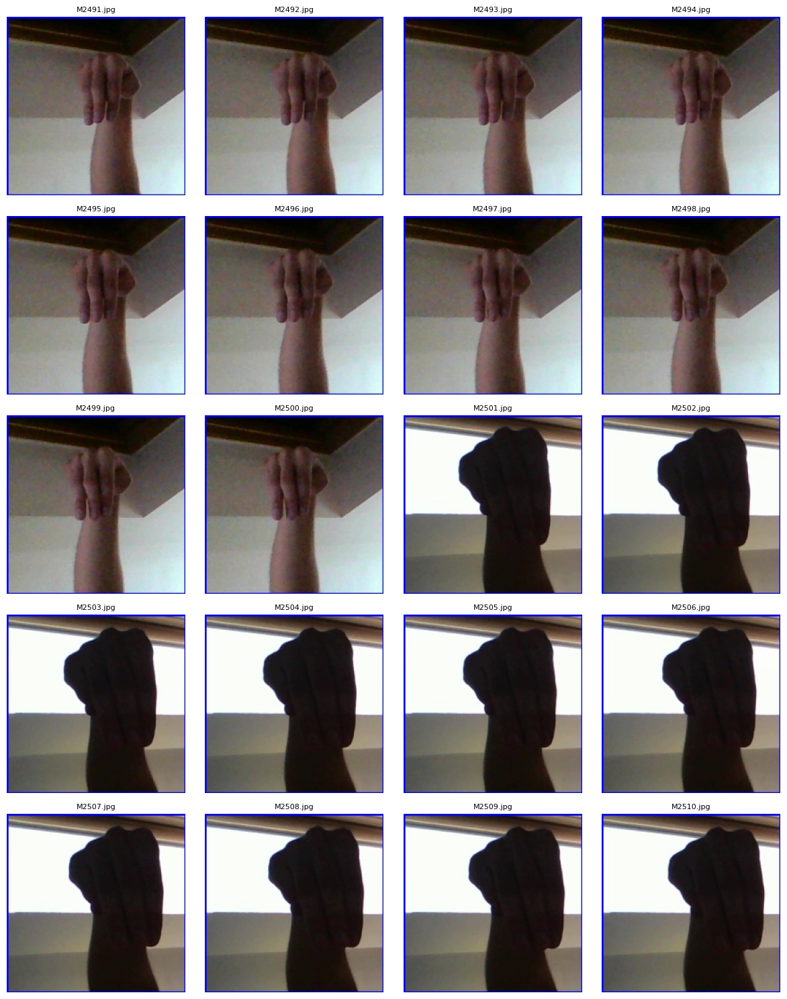

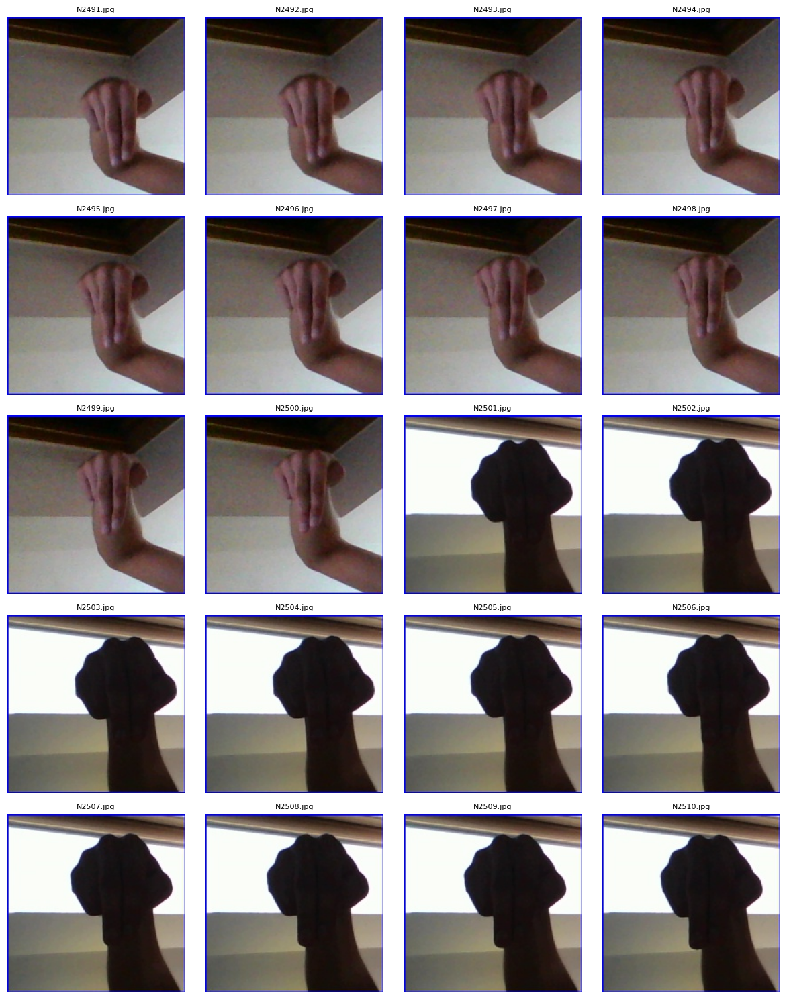

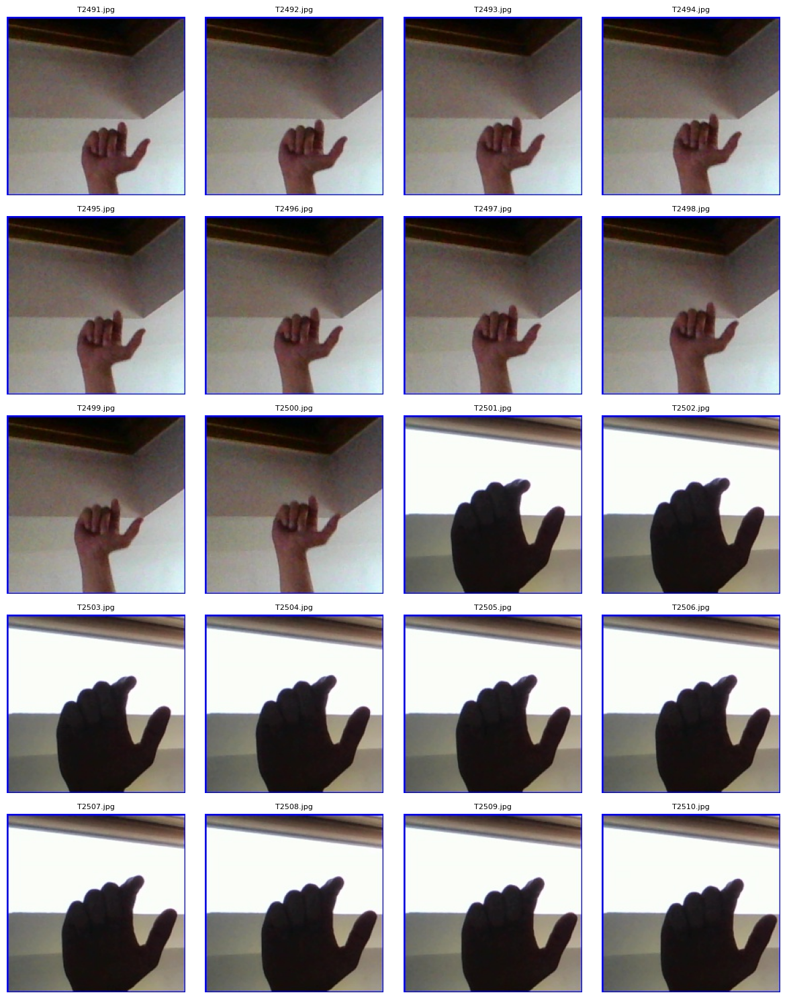

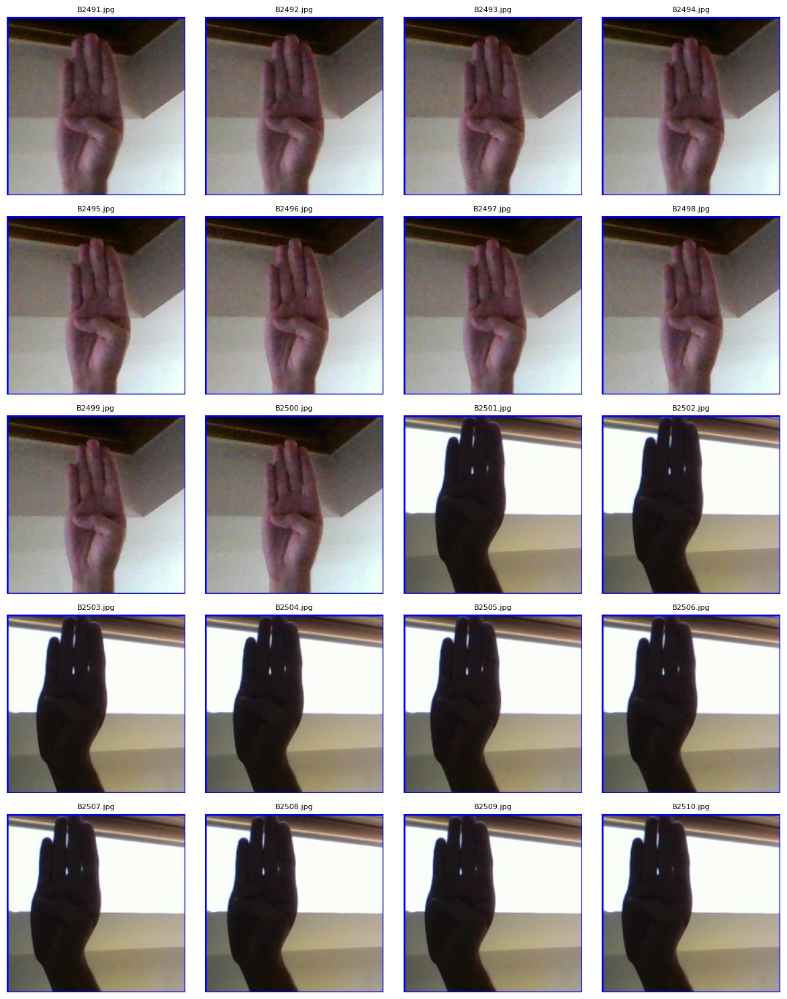

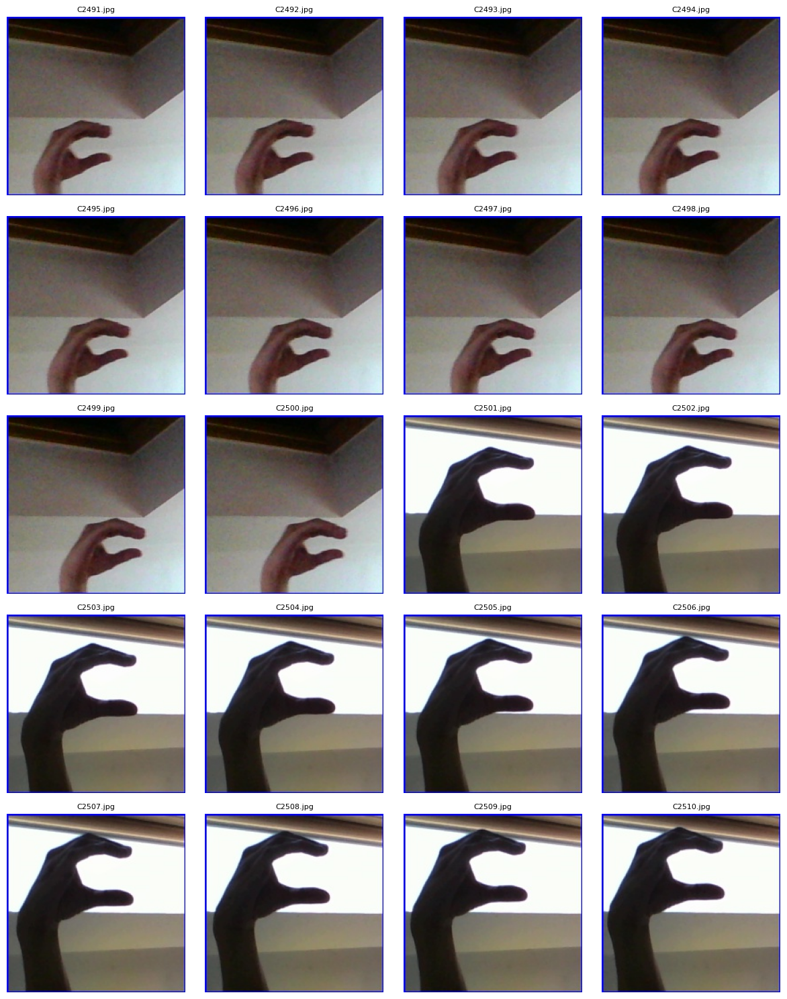

In [30]:
for class_name in ["M", "N", "T", "B", "C"]:
    show_sequence(
        df_train,
        class_name,
        start=2490,
        n=20
    )

## 10. Gán `ImageNumber` cho toàn bộ DataFrame

Từ đây, số thứ tự ảnh được lưu hẳn trong `df_train` để dùng cho việc tạo capture block.

Hàm extraction được định nghĩa lại theo dạng gọn hơn; đây là phần lặp nhẹ về code nhưng không thay đổi logic.


In [31]:

import re
from pathlib import Path

def extract_image_number(path):
    filename = Path(path).stem
    match = re.search(r'(\d+)$', filename)
    return int(match.group(1)) if match else None

df_train["ImageNumber"] = (
    df_train["Path"]
    .apply(extract_image_number)
)

### 10.1. 4 capture block cuối cùng

Sau toàn bộ visual + brightness + SSIM + cross-class verification, chốt:

- Block 1: 1–1000
- Block 2: 1001–2000
- Block 3: 2001–2500
- Block 4: 2501–3000



In [32]:
def assign_capture_block(n):
    if 1 <= n <= 1000:
        return 1
    elif 1001 <= n <= 2000:
        return 2
    elif 2001 <= n <= 2500:
        return 3
    elif 2501 <= n <= 3000:
        return 4
    return None

df_train["CaptureBlock"] = (
    df_train["ImageNumber"]
    .apply(assign_capture_block)
)

### 10.2. Kiểm tra phân bố block theo từng class

`groupby(["Class", "CaptureBlock"])` dùng để đảm bảo logic block áp dụng nhất quán cho cả 29 class.

**Output:** mỗi class có 1000/1000/500/500 ảnh ở bốn block. Đây là cấu trúc hoàn toàn đồng đều giữa các class.


In [33]:
block_distribution = (
    df_train
    .groupby(["Class", "CaptureBlock"])
    .size()
    .unstack(fill_value=0)
)

display(block_distribution)

CaptureBlock,1,2,3,4
Class,,,,
A,1000,1000,500,500
B,1000,1000,500,500
C,1000,1000,500,500
D,1000,1000,500,500
E,1000,1000,500,500
F,1000,1000,500,500
G,1000,1000,500,500
H,1000,1000,500,500
I,1000,1000,500,500


### 10.3. Kiểm tra tổng số ảnh theo block

**Output:**

- Block 1 = 29,000
- Block 2 = 29,000
- Block 3 = 14,500
- Block 4 = 14,500

Tổng = 87,000, khớp với dataset ban đầu. Không có ảnh bị mất trong quá trình gán block.


In [34]:
print(
    df_train["CaptureBlock"]
    .value_counts()
    .sort_index()
)

CaptureBlock
1    29000
2    29000
3    14500
4    14500
Name: count, dtype: int64


## 11. Group-aware Train/Validation split

Thay vì random từng ảnh, notebook giữ **Block 4 hoàn toàn cho validation** và dùng Blocks 1–3 cho train.

Lý do: các ảnh liền nhau có near-duplicate correlation mạnh. Random split có thể đưa hai frame gần như giống nhau vào cả train và validation, làm metric lạc quan giả tạo.

**Output:** Train = 72,500; Validation = 14,500.


In [35]:
train_df = (
    df_train[
        df_train["CaptureBlock"].isin([1, 2, 3])
    ]
    .reset_index(drop=True)
)

val_df = (
    df_train[
        df_train["CaptureBlock"] == 4
    ]
    .reset_index(drop=True)
)

print("Train:", len(train_df))
print("Validation:", len(val_df))

Train: 72500
Validation: 14500


### 11.1. Kiểm tra class balance sau split

**Output:**

- Train: 2,500 ảnh/class.
- Validation: 500 ảnh/class.

Min/max bằng nhau ở cả hai tập, nên split theo capture block vẫn giữ class balance hoàn hảo.


In [36]:
train_class_counts = (
    train_df["Class"]
    .value_counts()
    .sort_index()
)

val_class_counts = (
    val_df["Class"]
    .value_counts()
    .sort_index()
)

print("Train:")
display(train_class_counts)

print("Validation:")
display(val_class_counts)

print(
    "Train min/max:",
    train_class_counts.min(),
    train_class_counts.max()
)

print(
    "Validation min/max:",
    val_class_counts.min(),
    val_class_counts.max()
)

Train:


Class
A          2500
B          2500
C          2500
D          2500
E          2500
F          2500
G          2500
H          2500
I          2500
J          2500
K          2500
L          2500
M          2500
N          2500
O          2500
P          2500
Q          2500
R          2500
S          2500
T          2500
U          2500
V          2500
W          2500
X          2500
Y          2500
Z          2500
del        2500
nothing    2500
space      2500
Name: count, dtype: int64

Validation:


Class
A          500
B          500
C          500
D          500
E          500
F          500
G          500
H          500
I          500
J          500
K          500
L          500
M          500
N          500
O          500
P          500
Q          500
R          500
S          500
T          500
U          500
V          500
W          500
X          500
Y          500
Z          500
del        500
nothing    500
space      500
Name: count, dtype: int64

Train min/max: 2500 2500
Validation min/max: 500 500


### 11.2. Kiểm tra leakage trực tiếp giữa train và validation

Ba sanity check:

1. Train chỉ chứa Blocks 1,2,3.
2. Validation chỉ chứa Block 4.
3. Không có `Path` nào xuất hiện ở cả hai tập.

**Output:** `Path overlap = 0`. Đây là bằng chứng trực tiếp rằng cùng một file không bị lặp giữa train và validation.

> Hạn chế còn lại: split này là capture-block-disjoint, nhưng không thể khẳng định subject-disjoint vì dataset không cung cấp subject/session ID.


In [37]:
print(
    "Train blocks:",
    sorted(train_df["CaptureBlock"].unique())
)

print(
    "Validation blocks:",
    sorted(val_df["CaptureBlock"].unique())
)

overlap = (
    set(train_df["Path"])
    & set(val_df["Path"])
)

print(
    "Path overlap:",
    len(overlap)
)

Train blocks: [np.int64(1), np.int64(2), np.int64(3)]
Validation blocks: [np.int64(4)]
Path overlap: 0


## 12. Cài đặt `torchvision`

Cell này là environment setup để dùng `transforms`, `Dataset` utilities và các model pretrained sau này.

Nếu `torchvision` đã được cài trong kernel hiện tại thì không cần chạy lại mỗi lần. Output cho thấy package đã có sẵn.


In [38]:
import sys

print(sys.executable)
print(sys.version)

C:\Users\CUONG\AppData\Local\Programs\Python\Python312\python.exe
3.12.4 (tags/v3.12.4:8e8a4ba, Jun  6 2024, 19:30:16) [MSC v.1940 64 bit (AMD64)]


In [39]:
import torch
print(torch.__version__)
print(torch.ones(2))


2.14.0+cpu
tensor([1., 1.])


In [40]:
# %pip install torchvision --index-url https://download.pytorch.org/whl/cpu

In [41]:
import torchvision

## 13. Định nghĩa preprocessing và augmentation

Hai pipeline được tách riêng:

### Train transform
`Resize → RandomRotation → RandomAffine → ColorJitter → ToTensor → Normalize`

- Resize 200×200 → 224×224 để thống nhất input và tương thích tốt với pretrained backbone.
- Rotation ±10°, translation ±5%, scale 0.95–1.05 giúp giảm phụ thuộc vào vị trí/góc tay cố định.
- Brightness/contrast ±15% giúp tăng robustness trước thay đổi lighting.
- `ToTensor` chuyển `[H,W,C]` thành `[C,H,W]` và pixel về [0,1].
- `Normalize` dùng ImageNet mean/std, phù hợp cho transfer learning và giữ pipeline nhất quán giữa các model.

### Validation transform
Chỉ `Resize → ToTensor → Normalize`, **không augmentation ngẫu nhiên**, để validation metric ổn định và phản ánh dữ liệu thật.

> Visual sanity check ở cuối notebook cho thấy augmentation vẫn giữ được gesture. Có xuất hiện viền đen do rotation/affine mặc định; hiện mức độ chấp nhận được, nhưng có thể chỉnh `fill` nếu sau này thấy artifact này ảnh hưởng model.


In [42]:
from torchvision import transforms

IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomRotation(10),

    transforms.RandomAffine(
        degrees=0,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

### 13.1. Mã hóa label từ tên class sang integer

`CrossEntropyLoss` cần target dạng integer class index. Vì vậy notebook tạo:

- `class_to_idx`: tên class → số 0..28;
- `idx_to_class`: số → tên class, dùng để hiển thị prediction/visualization.

**Output:** 29 class được map nhất quán, `A=0` ... `space=28`.


In [43]:
class_names = sorted(
    df_train["Class"].unique()
)

class_to_idx = {
    class_name: idx
    for idx, class_name
    in enumerate(class_names)
}

idx_to_class = {
    idx: class_name
    for class_name, idx
    in class_to_idx.items()
}

print(class_to_idx)

{'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'J': 9, 'K': 10, 'L': 11, 'M': 12, 'N': 13, 'O': 14, 'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19, 'U': 20, 'V': 21, 'W': 22, 'X': 23, 'Y': 24, 'Z': 25, 'del': 26, 'nothing': 27, 'space': 28}


## 14. Custom PyTorch Dataset

`ASLDataset` là cầu nối giữa `DataFrame` và PyTorch.

Mỗi lần `__getitem__` được gọi:

1. lấy một dòng trong DataFrame;
2. mở ảnh theo `Path` và ép về RGB;
3. đổi label string sang integer;
4. áp dụng transform tương ứng;
5. trả về `(image, label)`.

Điểm quan trọng: dataset không load 72,500 ảnh vào RAM cùng lúc; ảnh chỉ được đọc khi DataLoader cần.


In [44]:
from torch.utils.data import Dataset
from PIL import Image

class ASLDataset(Dataset):
    def __init__(
        self,
        dataframe,
        class_to_idx,
        transform=None
    ):
        self.df = dataframe.reset_index(drop=True)
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(
            row["Path"]
        ).convert("RGB")

        label = self.class_to_idx[
            row["Class"]
        ]

        if self.transform:
            image = self.transform(image)

        return image, label

### 14.1. Tạo train dataset và validation dataset

Cả hai dùng cùng class mapping nhưng khác transform:

- train_dataset có augmentation ngẫu nhiên;
- val_dataset không augmentation.

Điều này tách rõ data augmentation khỏi quá trình đánh giá.


In [45]:
train_dataset = ASLDataset(
    train_df,
    class_to_idx,
    transform=train_transform
)

val_dataset = ASLDataset(
    val_df,
    class_to_idx,
    transform=val_transform
)

## 15. DataLoader và batching

DataLoader chia dữ liệu thành batch 64 ảnh.

- Train: `shuffle=True` để thứ tự sample thay đổi qua epoch.
- Validation: `shuffle=False` vì không cần random thứ tự khi evaluate.
- `num_workers=0`, `pin_memory=False` là lựa chọn ổn định cho Jupyter/Windows trong môi trường hiện tại; trước đó multiprocessing có thể làm batch đầu tiên treo/chậm.

Với 72,500 ảnh và batch size 64, mỗi epoch có khoảng 1,133 train batches.


In [46]:
from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

### 15.1. Sanity check một batch

Lấy batch đầu tiên để kiểm tra pipeline end-to-end trước khi train model.

**Output:**

- Images: `[64, 3, 224, 224]` — đúng format `[B,C,H,W]`.
- Labels: `[64]` — mỗi ảnh có một class index.
- Min ≈ -2.118, Max ≈ 2.64 — hợp lý sau ImageNet normalization; giá trị âm không phải lỗi.

Nếu cell này chạy đúng, path, Dataset, transform, label mapping và DataLoader đều đã hoạt động cùng nhau.


In [47]:
images, labels = next(
    iter(train_loader)
)

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Min:", images.min().item())
print("Max:", images.max().item())

Images shape: torch.Size([64, 3, 224, 224])
Labels shape: torch.Size([64])
Min: -2.1179039478302
Max: 2.640000104904175


## 16. Visual sanity check sau augmentation

Vì tensor đã normalize nên trước khi hiển thị cần **denormalize** về khoảng màu nhìn được.

Cell lấy một batch train, đảo normalization và hiển thị 8 ảnh cùng label.

**Mục đích:** kiểm tra bằng mắt rằng augmentation không làm:

- mất/cắt bàn tay;
- biến dạng gesture quá mức;
- làm ảnh quá tối/sáng;
- sai label.

Output hiện tại nhìn hợp lý: gesture vẫn nhận diện được và label khớp. Viền đen ở một số góc là artifact do rotation/affine; có thể theo dõi thêm nhưng chưa phải vấn đề nghiêm trọng.


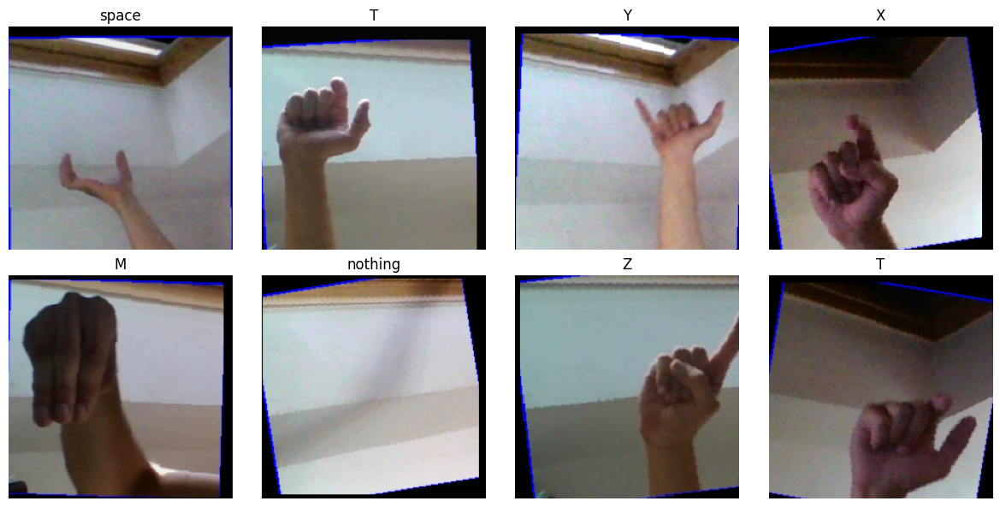

In [48]:
import matplotlib.pyplot as plt
import numpy as np

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

def denormalize(img_tensor):
    img = img_tensor.permute(1, 2, 0).numpy()
    img = img * std + mean
    img = np.clip(img, 0, 1)
    return img

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flatten()):
    img = denormalize(images[i])
    label = idx_to_class[labels[i].item()]

    ax.imshow(img)
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 17. Tổng kết Data Understanding & Preprocessing

Notebook đã hoàn thành các bước cần thiết trước khi xây mô hình:

1. **Dataset structure:** 87,000 ảnh, 29 class, 3,000 ảnh/class.
2. **Image quality:** sample audit 2,900 ảnh đều 200×200 RGB; full integrity scan cho thấy 87,000 ảnh đều đọc được, không phát hiện corruption.
3. **Exact duplicates:** 0 duplicate groups theo MD5.
4. **Near-duplicates:** có tương quan rất mạnh giữa các ảnh liên tiếp; vì vậy không dùng random image-wise split.
5. **Capture-regime boundaries:** được xác minh bằng visual inspection, brightness, SSIM và cross-class inspection tại 1000, 2000, 2500.
6. **Final blocks:** 1–1000, 1001–2000, 2001–2500, 2501–3000.
7. **Split:** Train = Blocks 1–3 (72,500); Validation = Block 4 (14,500); class balance giữ nguyên và path overlap = 0.
8. **Preprocessing:** resize 224×224, train-only augmentation, tensor conversion, ImageNet normalization.
9. **PyTorch input pipeline:** custom Dataset + DataLoader hoạt động đúng; batch shape `[64,3,224,224]`.
10. **Visual sanity check:** augmentation vẫn bảo toàn hình thái gesture.

### Vấn đề và cách xử lý

| Vấn đề | Bằng chứng | Cách xử lý |
|---|---|---|
| Exact duplicate | MD5 duplicate groups = 0 | Không cần xóa file |
| Near-duplicate / sequential correlation | Visual sequence + SSIM cao giữa ảnh liên tiếp | Group-aware split theo capture block |
| Capture-condition shift | Discontinuity quanh 1000/2000/2500 | Tạo 4 CaptureBlock |
| Brightness thay đổi | Brightness drift trong từng vùng | Không dùng brightness một mình để chia block |
| SSIM thấp do hand motion | Một số cặp 243x–248x | Xác minh lại bằng visual inspection trước khi gọi là boundary |
| Nguy cơ background shortcut | Background/camera khá đồng nhất | Augmentation, external test và Grad-CAM ở giai đoạn sau |
| Class imbalance | 3,000 ảnh/class | Không cần weighting/resampling |
| Corrupted files | 0/87,000 | Không cần loại ảnh |
| Leakage train/validation | Path overlap = 0 và block-disjoint | Giữ Block 4 riêng cho validation |

Đon